# 13 - ML Curve Imputation

**Part B - Petrophys Curriculum**

Real well-log data is full of holes: a tool fails over an interval, a curve was
only run over part of the hole, or it was never run at all. Classic fixes -
interpolation, constant fill, or dropping the interval - either invent structure
or throw away depth. **Machine-learning curve imputation** instead *predicts* the
missing samples from the curves that **are** present, by learning how the logs
relate to each other where all of them were measured.

In `petrophys` this is one function, `pp.impute(well, curve)`. It trains a
gradient-boosted tree model on the fly, from this well and any offset wells you
pass, and fills the gaps of one curve. This lesson shows how to:

- Blank a block of a real, measured curve, rebuild it, and **score the
  prediction against the values we hid**.
- Fill a well's **genuine** gaps, and read the warning `pp.impute` gives when
  the gap lies outside what the model has seen.
- **Rebuild a curve a well does not have** from offset wells in the same field.
- Write the result to a LAS file with `output=`.
- Decide *when* imputation is appropriate and *when it is risky*.

## Learning goals

By the end of this lesson you will be able to:

- Call `pp.impute(well, curve)` and find its result in the `<CURVE>_IMPUTED`
  curve, with the measured samples left exactly as recorded.
- Validate imputation by blanking known data and computing MAE, RMSE, bias and
  $R^2$ against the hidden values - and explain why one test block is not enough.
- Read the extrapolation warning and trace it back to the input logs that cause it.
- Rebuild an absent curve with `train_wells=` and judge the result.
- Write an imputed well to LAS with `output=` and read it back.
- Explain the appropriateness and the risks of ML curve imputation.

## How `pp.impute` works

```python
pp.impute(well, curve, *, train_wells=None, output=None) -> Well
```

`well` can also be a well file or an interpretation result; `pp.impute` returns
what it was given, so a result comes back as a result.

1. **Training data.** Wherever `curve` was measured - in `well` itself and in
   every well in `train_wells` - the measured values become the training targets.
2. **Inputs.** The other logs are the inputs: whichever of GR, SP, CALI, BS,
   RHOB, DRHO, NPHI, PEF, DTC, DTS, RDEP, RMED, RSHA and RXO are present where
   the curve is missing and in every training well. Depth is *not* an input.
3. **Model.** A scikit-learn `HistGradientBoostingRegressor` is fitted to that
   data each time you call the function. Nothing is stored between calls.
   Resistivity targets are modelled as $\log_{10}$, since they span decades.
4. **Output.** The well gains `<CURVE>_IMPUTED`: the measured values where the
   curve has them, the predictions in its gaps. The original curve is untouched.
   With `output=` the well is also written to a LAS file.

Three rules follow from this design:

- **A curve the well does not have needs `train_wells`.** With nothing measured
  in the well itself, the model can only learn from other wells; without them
  `pp.impute` raises `ValueError`.
- **At least 200 measured samples** are needed to train, otherwise `ValueError`.
- **Trees do not extrapolate.** Where an input log falls outside the range it
  had in the training data, the prediction stays near the edge of what the
  model has seen. `pp.impute` warns with the number of such samples.

### Prerequisites

Assumes the Part A loading/QAQC lessons (01, 02). `pp.impute` needs
scikit-learn, which the machine-learning extra installs. Install it in the same
environment as the notebook kernel:

```bash
pip install "petrophys[ml]"
```

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()

import copy
import tempfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys as pp

print("petrophys", pp.__version__)

petrophys 3.0.0


Two small helpers keep the scoring and the warnings readable. `score` compares
predictions with the hidden truth. `run_impute` calls `pp.impute` and collects
the warnings it raises, so we can print and discuss them.

In [2]:
def score(truth, predicted):
    # MAE, RMSE, bias (predicted - truth) and R^2 of predicted against truth.
    err = predicted - truth
    r2 = 1.0 - np.sum(err ** 2) / np.sum((truth - truth.mean()) ** 2)
    return {"n": int(truth.size), "MAE": float(np.mean(np.abs(err))),
            "RMSE": float(np.sqrt(np.mean(err ** 2))), "bias": float(np.mean(err)),
            "R2": float(r2)}


def run_impute(*args, **kwargs):
    # pp.impute, returning the well and the messages of any warnings it raised.
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        result = pp.impute(*args, **kwargs)
    return result, [str(w.message) for w in caught]

## 1. A controlled experiment: blank, impute, score

We load **15/9-14**, a GeoLink North Sea well whose neutron log (`NPHI`) was
recorded over almost the whole hole. We then:

1. Keep the measured NPHI as ground truth.
2. Blank a contiguous 100 m block in the middle of the log on a copy of the well.
3. Rebuild it with `pp.impute`, which learns NPHI from the rest of this well.
4. Compare the rebuilt block with the values we hid.

In [3]:
well = pp.read(pp.sample("15_9-14"))
depth = np.asarray(well.depth, dtype=float)
nphi = np.asarray(well.get("NPHI").data, dtype=float).copy()
measured = np.flatnonzero(np.isfinite(nphi))

print("Well   :", well.name, "| depth unit:", well.depth_unit)
print("Curves :", ", ".join(well.curves))
print("NPHI   : %d of %d samples measured, %.1f - %.1f m"
      % (measured.size, well.n_samples, depth[measured[0]], depth[measured[-1]]))

Well   : 15/9-14 | depth unit: m
Curves : LITHOLOGY_GEOLINK, CALI, DRHO, NPHI, RHOB, PEF, GR, DTC, DTE, RDEP, SP, RSHA, RXO, RMED, BS
NPHI   : 20309 of 20311 samples measured, 480.4 - 3575.3 m


In [4]:
BLOCK_LENGTH = 100.0                                   # metres
block_top = depth[measured[measured.size // 2]]        # middle of the measured log
block_bottom = block_top + BLOCK_LENGTH
blank_mask = (depth >= block_top) & (depth <= block_bottom) & np.isfinite(nphi)

# Work on a copy so the original well stays intact.
gapped = copy.deepcopy(well)
values = nphi.copy()
values[blank_mask] = np.nan
gapped.get("NPHI").data = values

print("Blanked %.1f - %.1f m: %d samples" % (block_top, block_bottom, blank_mask.sum()))
print("NPHI nulls after blanking:", int(np.isnan(values).sum()))

Blanked 2027.8 - 2127.8 m: 657 samples
NPHI nulls after blanking: 659


### Running the imputer

One call. The function returns the well, now carrying `NPHI_IMPUTED`.

In [5]:
gapped, messages = run_impute(gapped, "NPHI")

nphi_imputed = np.asarray(gapped.get("NPHI_IMPUTED").data, dtype=float)
kept = np.isfinite(nphi) & ~blank_mask

print("New curve                 :", "NPHI_IMPUTED" in gapped.curves)
print("Measured samples unchanged:", np.array_equal(nphi_imputed[kept], nphi[kept]))
print("Nulls left in NPHI        :", int(np.isnan(gapped.get("NPHI").data).sum()))
print("Nulls left in NPHI_IMPUTED:", int(np.isnan(nphi_imputed).sum()))
for message in messages:
    print("Warning:", message)

New curve                 : True
Measured samples unchanged: True
Nulls left in NPHI        : 659
Nulls left in NPHI_IMPUTED: 0


The original `NPHI` still carries its gap; `NPHI_IMPUTED` is complete and agrees
with `NPHI` exactly wherever NPHI was measured. The function fills *every* null
sample, so the total in the warning also includes the two nulls the log had
before we blanked anything. A small number of out-of-range samples, as here, is
normal: a 100 m block can easily hold a few readings more extreme than anything
in the rest of the well. It is when the warning flags a large share of the
imputed samples that you should stop and look (section 3).

## 2. Scoring against ground truth

We score strictly over the blanked samples. Those values were hidden from the
model, and - unlike a random sample split - the block is a contiguous interval,
which is what a real tool failure looks like.

In [6]:
block = score(nphi[blank_mask], nphi_imputed[blank_mask])

print("Blank-and-restore over %d samples (%.0f - %.0f m)" % (block["n"], block_top, block_bottom))
print("  MAE  : %.4f v/v" % block["MAE"])
print("  RMSE : %.4f v/v" % block["RMSE"])
print("  Bias : %+.4f v/v  (imputed - truth)" % block["bias"])
print("  R^2  : %.3f" % block["R2"])
print()
print("  NPHI spans %.2f - %.2f v/v in the block, so RMSE is %.1f%% of that range."
      % (nphi[blank_mask].min(), nphi[blank_mask].max(),
         100 * block["RMSE"] / (nphi[blank_mask].max() - nphi[blank_mask].min())))

Blank-and-restore over 657 samples (2028 - 2128 m)
  MAE  : 0.0206 v/v
  RMSE : 0.0278 v/v
  Bias : -0.0047 v/v  (imputed - truth)
  R^2  : 0.879

  NPHI spans 0.27 - 0.56 v/v in the block, so RMSE is 9.8% of that range.


### Overlay: imputed vs actual

Truth in black, imputed in red, over the blanked interval. Where the two lie on
top of each other, the model reproduces the measured structure.

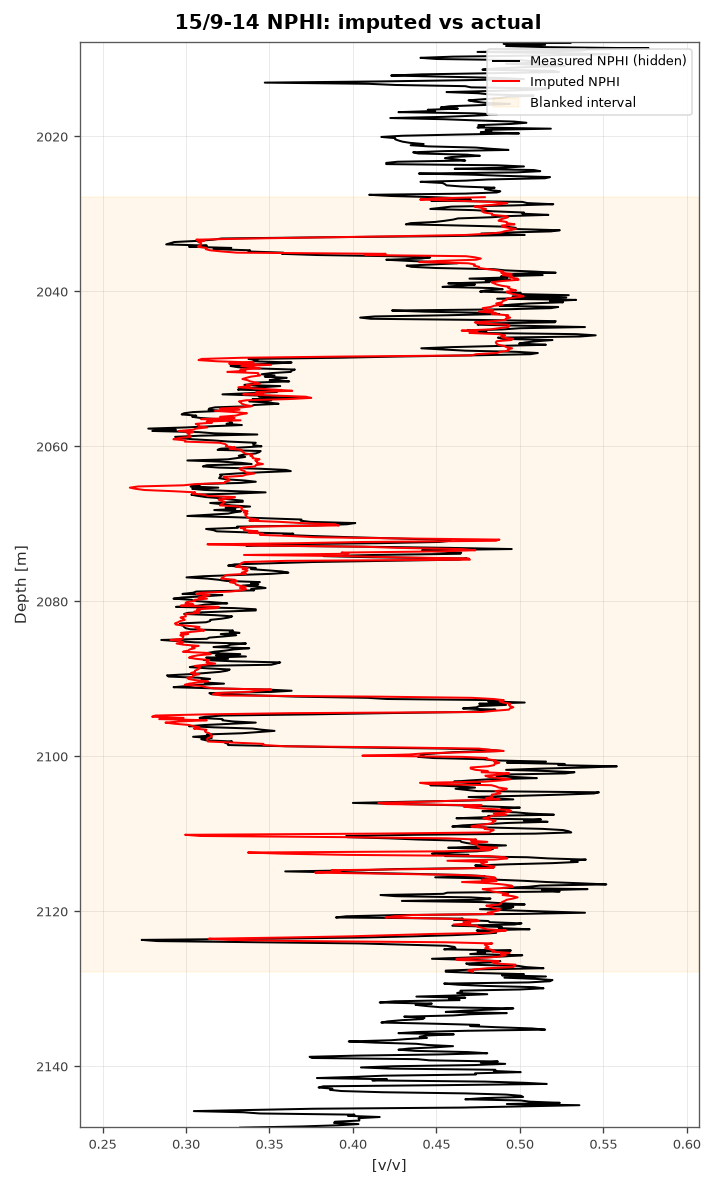

In [7]:
from petrophys.visualization import LogPlot

# Attach the truth and the imputed block as curves so LogPlot can draw them.
gapped.add_curve("NPHI_TRUTH", nphi, unit="v/v")
gapped.add_curve("NPHI_BLOCK", np.where(blank_mask, nphi_imputed, np.nan), unit="v/v")

window = (depth >= block_top - 20) & (depth <= block_bottom + 20)
x_lo = float(np.nanmin(np.r_[nphi[window], nphi_imputed[blank_mask]])) - 0.03
x_hi = float(np.nanmax(np.r_[nphi[window], nphi_imputed[blank_mask]])) + 0.03

lp = LogPlot(gapped, figsize=(6, 10))
lp.create_figure(n_tracks=1)
lp.add_curve(0, "NPHI_TRUTH", color="black", linewidth=1.2, label="Measured NPHI (hidden)",
             xlim=(x_lo, x_hi))
lp.add_curve(0, "NPHI_BLOCK", color="red", linewidth=1.2, label="Imputed NPHI")
lp.axes[0].axhspan(block_top, block_bottom, color="orange", alpha=0.08, label="Blanked interval")
lp.axes[0].legend(loc="upper right", fontsize=8)
lp.set_depth_range(block_top - 20, block_bottom + 20)
lp.add_title("15/9-14 NPHI: imputed vs actual")
lp.show()

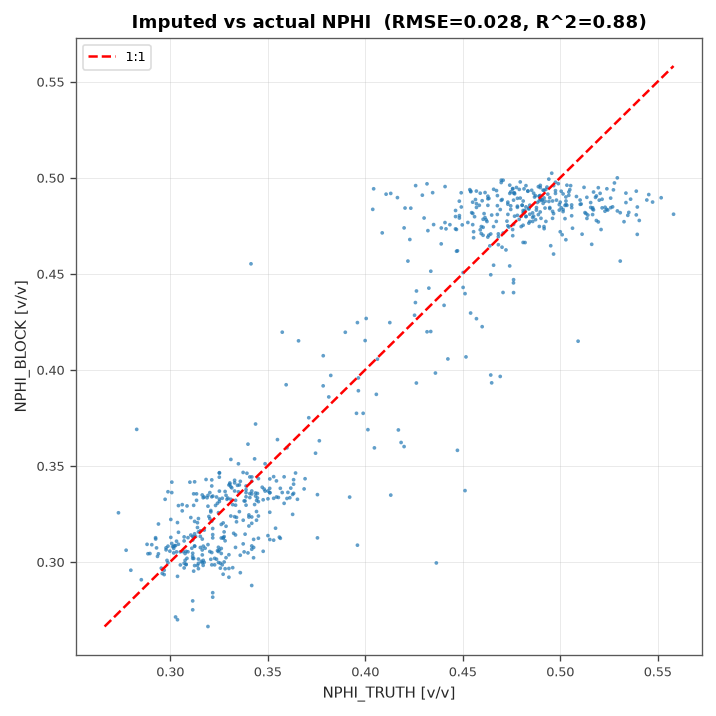

In [8]:
from petrophys.visualization import create_crossplot

t, p = nphi[blank_mask], nphi_imputed[blank_mask]
lo, hi = float(min(t.min(), p.min())), float(max(t.max(), p.max()))

cp = create_crossplot(
    gapped, "NPHI_TRUTH", "NPHI_BLOCK", depth_range=(block_top, block_bottom),
    title="Imputed vs actual NPHI  (RMSE=%.3f, R^2=%.2f)" % (block["RMSE"], block["R2"]),
    figsize=(6, 6),
)
cp.add_line([lo, hi], [lo, hi], color="red", linestyle="--", linewidth=1.5, label="1:1")
cp.show()

### One block is not a verdict

The score depends heavily on *which* interval is missing. A block in a
lithology the rest of the well samples well is easy; a block in a rock type
that occurs nowhere else is hard. So we repeat the experiment for five 100 m
blocks spread down the log and look at the spread, not just the best case.

In [9]:
rows = []
for fraction in (0.2, 0.35, 0.5, 0.65, 0.8):
    top = depth[measured[int(fraction * measured.size)]]
    mask = (depth >= top) & (depth <= top + BLOCK_LENGTH) & np.isfinite(nphi)
    trial = copy.deepcopy(well)
    blanked = nphi.copy()
    blanked[mask] = np.nan
    trial.get("NPHI").data = blanked
    trial, _ = run_impute(trial, "NPHI")
    predicted = np.asarray(trial.get("NPHI_IMPUTED").data, dtype=float)
    rows.append({"block": "%.0f-%.0f m" % (top, top + BLOCK_LENGTH),
                 **score(nphi[mask], predicted[mask])})

blocks = pd.DataFrame(rows).set_index("block")
print(blocks.round(3).to_string())
print()
print("Median R^2 over the five blocks: %.2f" % blocks["R2"].median())
print("The section 1 block ranks %d of 5 by R^2."
      % (int((blocks["R2"] > block["R2"] + 1e-9).sum()) + 1))

               n    MAE   RMSE   bias     R2
block                                       
1099-1199 m  657  0.038  0.049 -0.007  0.326
1564-1664 m  657  0.025  0.032  0.009  0.053
2028-2128 m  657  0.021  0.028 -0.005  0.879
2492-2592 m  657  0.038  0.051  0.002  0.249
2956-3056 m  657  0.016  0.021  0.006  0.500

Median R^2 over the five blocks: 0.33
The section 1 block ranks 1 of 5 by R^2.


Read the table before quoting any single number. The block of section 1 turns
out to be the easiest of the five, and the median $R^2$ is far lower. The
spread from the best to the worst block is wide, and an $R^2$ near zero means
that block's prediction is no better than drawing a straight line at its mean.
The MAE and RMSE vary much less than $R^2$: blocks where NPHI barely changes
have little variance to explain, so a small absolute error can still give a
low $R^2$. A blank-and-restore
test gives you an error *estimate* for this well and this curve; the honest
number to carry is the typical one, not the best one.

## 3. Filling a well's genuine gaps - and reading the warning

**16/7-1** has a real gap: its density log (`RHOB`) was only recorded over the
lower part of the hole. Here there is no truth to score against, so the warning
is our main source of evidence.

In [10]:
w167 = pp.read(pp.sample("16_7-1"))
d167 = np.asarray(w167.depth, dtype=float)
rhob = np.asarray(w167.get("RHOB").data, dtype=float).copy()
rhob_measured = np.isfinite(rhob)
first = np.flatnonzero(rhob_measured)[0]

print("16/7-1 logged %.1f - %.1f m, %d samples" % (w167.top, w167.bottom, w167.n_samples))
print("RHOB measured from %.1f m: %d samples; null: %d samples"
      % (d167[first], rhob_measured.sum(), (~rhob_measured).sum()))

w167, messages = run_impute(w167, "RHOB")
for message in messages:
    print("Warning:", message)

16/7-1 logged 367.9 - 2651.7 m, 14986 samples
RHOB measured from 1428.8 m: 7980 samples; null: 7006 samples


Every imputed sample is flagged. To see why, compare each input log
where RHOB was measured (the training data) with the same log in the gap. The
last column applies the warning's test: a gap sample counts as outside when it
lies beyond the 1st-99th percentile range of the training data, widened by 10%
of that range.

In [11]:
inputs = ["GR", "SP", "CALI", "BS", "DTC", "RDEP", "RMED", "RSHA"]
gap = ~rhob_measured
rows = []
for name in inputs:
    v = np.asarray(w167.get(name).data, dtype=float)
    train, filled = v[rhob_measured], v[gap]
    train, filled = train[np.isfinite(train)], filled[np.isfinite(filled)]
    low, high = np.percentile(train, 1), np.percentile(train, 99)
    span = high - low
    outside = (filled < low - 0.1 * span) | (filled > high + 0.1 * span)
    rows.append({"input": name,
                 "coverage with RHOB %": 100.0 * train.size / rhob_measured.sum(),
                 "coverage in gap %": 100.0 * filled.size / gap.sum(),
                 "median with RHOB": np.median(train), "median in gap": np.median(filled),
                 "gap outside range %": 100.0 * outside.mean()})
print(pd.DataFrame(rows).round(2).to_string(index=False))

input  coverage with RHOB %  coverage in gap %  median with RHOB  median in gap  gap outside range %
   GR                 99.12              99.36             13.86          86.48                46.72
   SP                100.00              99.99             75.58          79.03                 0.63
 CALI                100.00             100.00              9.88          12.02                 2.78
   BS                100.00             100.00              8.50          12.25                99.36
  DTC                 97.83              23.12             24.55          44.83                 0.06
 RDEP                 97.99              99.30              1.16           1.20                 0.00
 RMED                  1.75              99.36              0.78           1.40                88.19
 RSHA                 99.96              99.36              1.12           1.12                 0.00


The table tells the geological story behind the warning:

- **BS (bit size).** The shallow gap was drilled with a larger bit than the
  section where density was logged, so practically every gap sample has a bit
  size the model has never seen.
- **RMED.** The medium resistivity was recorded almost only in the shallow
  section. Where RHOB was measured it is nearly absent, so the model has
  learned very little about it.
- **GR.** The measured-density section is dominated by low-GR evaporites (the
  Zechstein salt; case study CS4 shows this), while the gap is shallow,
  higher-GR mudstone. The model learned density from different rocks.

None of this stops `pp.impute` from producing numbers, and the plot below shows
that they look like a density log. But they are a guess outside the model's
experience: here the imputed shallow RHOB should not be used for porosity.

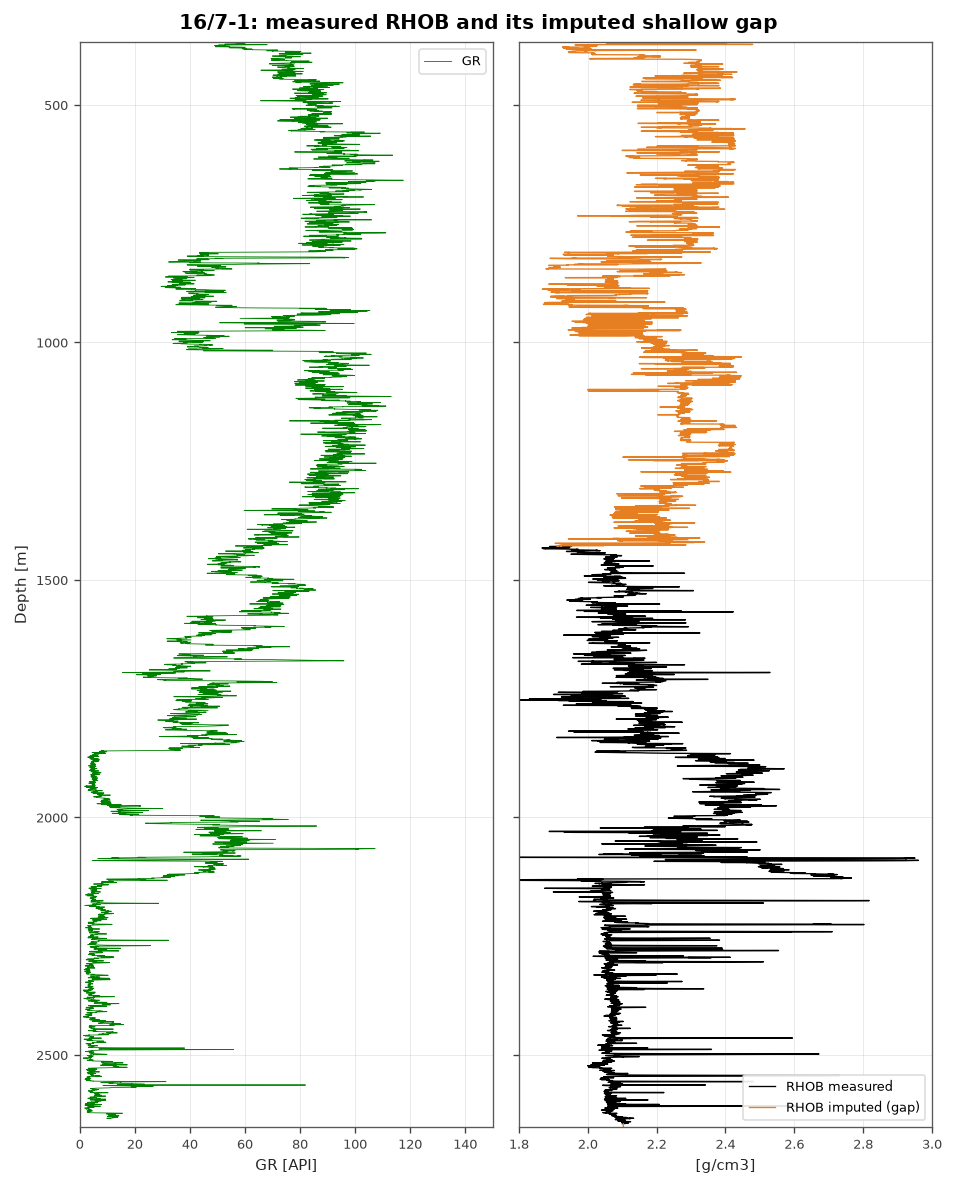

In [12]:
from petrophys.visualization import LogPlot

rhob_imputed = np.asarray(w167.get("RHOB_IMPUTED").data, dtype=float)
w167.add_curve("RHOB_GAPFILL", np.where(gap, rhob_imputed, np.nan), unit="g/cm3")

lp = LogPlot(w167, figsize=(8, 10))
lp.create_figure(n_tracks=2)
lp.add_curve(0, "GR", color="green", xlim=(0, 150), label="GR")
lp.add_curve(1, "RHOB", color="black", linewidth=0.8, xlim=(1.8, 3.0), label="RHOB measured")
lp.add_curve(1, "RHOB_GAPFILL", color="#e67e22", linewidth=0.8, label="RHOB imputed (gap)")
lp.axes[1].legend(loc="lower right", fontsize=8)
lp.set_depth_range()
lp.add_title("16/7-1: measured RHOB and its imputed shallow gap")
lp.show()

## 4. Rebuilding a whole curve from offset wells

Sometimes a curve was never run in a well at all. With nothing to learn from
in the well itself, `pp.impute` needs **training wells** that have the curve -
ideally from the same field, so they sample the same rocks.

The bundled **COSTA** dataset gives us 17 wells (HW-*) from one field. We remove
a curve from one well, rebuild it from the other 16, and compare with the
removed log. First, the error you get without training wells:

In [13]:
costa_names = [n for n in pp.list_samples() if n.startswith("HW-")]
costa = {name: pp.read(pp.sample(name)) for name in costa_names}
print(len(costa), "COSTA wells:", ", ".join(costa_names))
print("Curves in HW-24:", ", ".join(costa["HW-24"].curves), "| depth unit:",
      costa["HW-24"].depth_unit)
print()
for curve in ("RHOB", "NPHI", "DT"):
    with_data = [n for n, w in costa.items() if w.get(curve).valid_count() > 0]
    print("%-4s has data in %2d wells" % (curve, len(with_data)))

blind = copy.deepcopy(costa["HW-24"])
blind.remove_curve("RHOB")
try:
    pp.impute(blind, "RHOB")
except ValueError as exc:
    print()
    print("ValueError:", exc)

17 COSTA wells: HW-10, HW-24, HW-25, HW-26, HW-27, HW-28, HW-29, HW-3, HW-30, HW-31, HW-32, HW-4, HW-5, HW-6, HW-7, HW-8, HW-9
Curves in HW-24: GR, RHOB, NPHI, DT, PHIE_CC, RT, SW_INPUT, PERM_CC | depth unit: ft

RHOB has data in 17 wells
NPHI has data in 17 wells
DT   has data in  7 wells

ValueError: HW-24 has no RHOB curve; pass train_wells= with wells that have it


Only a minority of the wells carry sonic (`DT`) data, so a rebuilt DT learns
from far fewer wells than RHOB or NPHI. We rebuild three curves, each in a
different well, always training on all the *other* COSTA wells:

In [14]:
def rebuild(target_name, curve):
    # Remove `curve` from one COSTA well and rebuild it from the other wells.
    target = copy.deepcopy(costa[target_name])
    truth = np.asarray(target.get(curve).data, dtype=float).copy()
    target.remove_curve(curve)
    offsets = [w for name, w in costa.items() if name != target_name]
    rebuilt, messages = run_impute(target, curve, train_wells=offsets)
    predicted = np.asarray(rebuilt.get(curve + "_IMPUTED").data, dtype=float)
    ok = np.isfinite(truth) & np.isfinite(predicted)
    return rebuilt, truth, predicted, score(truth[ok], predicted[ok]), messages


cases = [("HW-24", "RHOB"), ("HW-31", "NPHI"), ("HW-27", "DT")]
rebuilt = {}
rows = []
for name, curve in cases:
    well_out, truth, predicted, stats, messages = rebuild(name, curve)
    rebuilt[(name, curve)] = (well_out, truth, predicted)
    n_train = sum(w.get(curve).valid_count() > 0 for n, w in costa.items() if n != name)
    rows.append({"well": name, "curve": curve, "unit": well_out.get(curve + "_IMPUTED").unit,
                 "wells with data": n_train, **stats})
    for message in messages:
        print("Warning:", message)

print()
print(pd.DataFrame(rows).round(3).to_string(index=False))


 well curve  unit  wells with data   n   MAE  RMSE   bias    R2
HW-24  RHOB g/cm3               16 433 0.036 0.059  0.003 0.879
HW-31  NPHI   v/v               16 421 0.018 0.023 -0.011 0.941
HW-27    DT us/ft                6 409 6.402 7.335  6.380 0.500


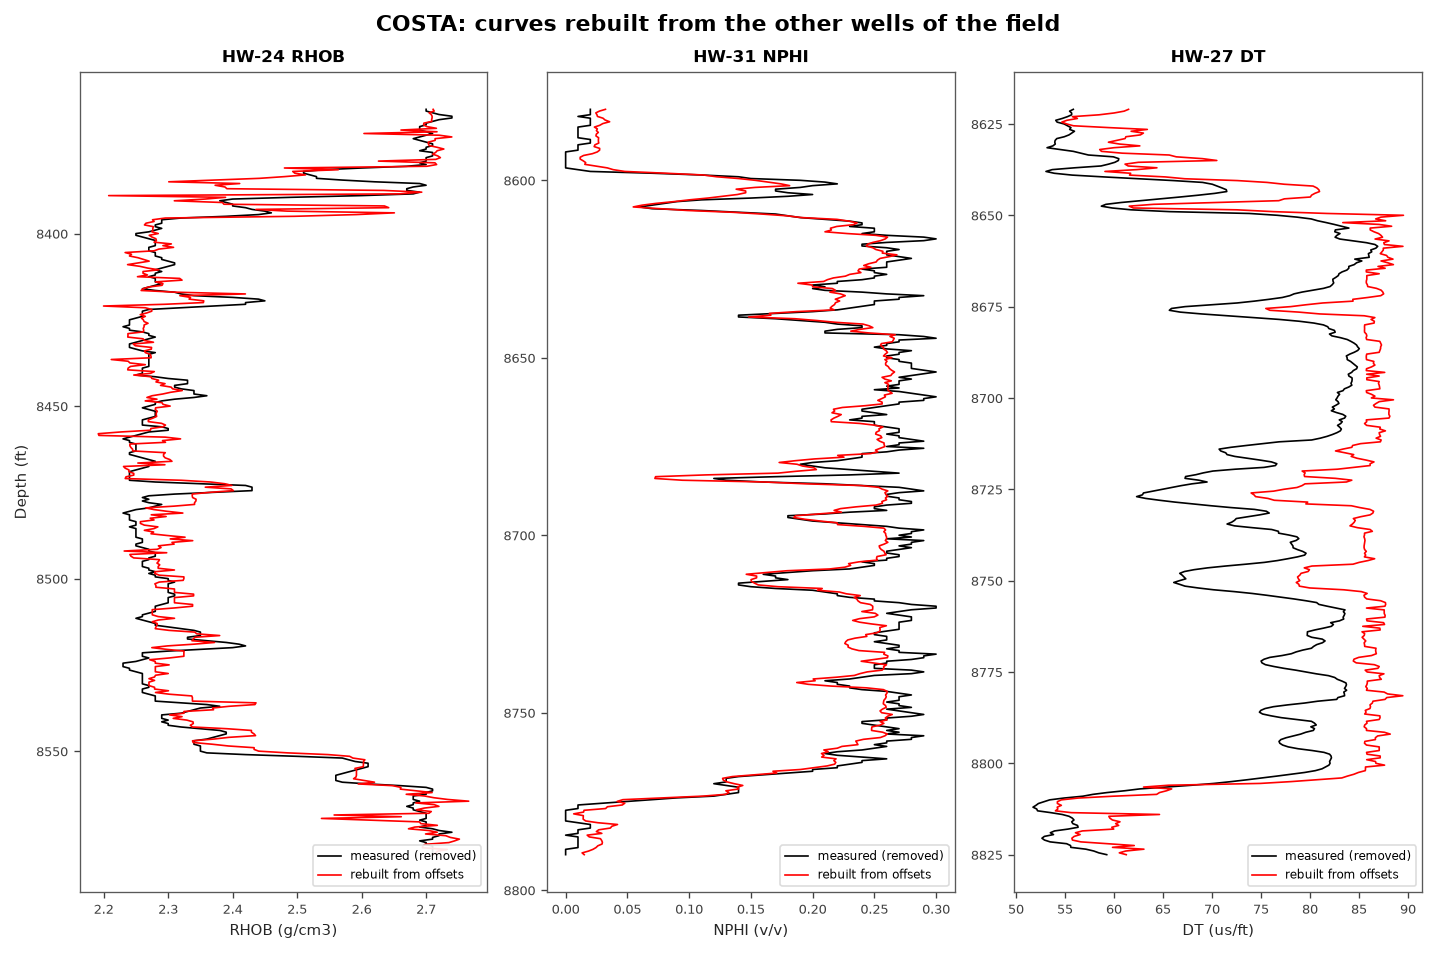

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 8))
for ax, (name, curve) in zip(axes, cases):
    well_out, truth, predicted = rebuilt[(name, curve)]
    d = np.asarray(well_out.depth, dtype=float)
    ax.plot(truth, d, color="black", lw=1.0, label="measured (removed)")
    ax.plot(predicted, d, color="red", lw=1.0, label="rebuilt from offsets")
    ax.set_title("%s %s" % (name, curve), fontsize=10)
    ax.set_xlabel("%s (%s)" % (curve, well_out.get(curve + "_IMPUTED").unit))
    ax.invert_yaxis()
    ax.legend(loc="lower right", fontsize=7)
axes[0].set_ylabel("Depth (%s)" % costa["HW-24"].depth_unit)
fig.suptitle("COSTA: curves rebuilt from the other wells of the field")
plt.tight_layout()
plt.show()

In one field with consistent logging, density and neutron rebuild well from the
other logs, because they are strongly coupled to each other and to the gamma
ray. The sonic is harder: fewer wells carry it, so the model has less to learn
from. The rebuilt DT follows the main breaks but reads systematically slow over
much of HW-27 (the positive bias in the table), and the warning flags more of
its samples. Same function, same field - the quality
depends on how much training data there is and how strongly the curve is tied
to the inputs.

Offset wells only help when they resemble the target. Wells from another basin,
or from a different part of the stratigraphy, teach the model the wrong
relations, and the extrapolation warning will only catch the part of that
mismatch that shows up as out-of-range inputs.

## 5. File-in / file-out with `output=`

For batch or pipeline use, `pp.impute` also accepts a file path for the well
and writes the result to LAS when you pass `output=`. Here we impute the 16/7-1
RHOB straight from the bundled file into a temporary LAS and read it back.

In [16]:
with tempfile.TemporaryDirectory() as folder:
    las_path = Path(folder) / "16_7-1_rhob_imputed.las"
    in_memory, messages = run_impute(pp.sample("16_7-1"), "RHOB", output=las_path)
    print("Wrote %s (%.1f MB)" % (las_path.name, las_path.stat().st_size / 1e6))
    print("Warnings raised:", len(messages))

    back = pp.read(las_path)
    curve = back.get("RHOB_IMPUTED")
    print("Curves in the file:", ", ".join(back.curves))
    print("RHOB_IMPUTED unit / description: %s / %s" % (curve.unit, curve.metadata.description))
    a = np.asarray(curve.data, dtype=float)
    b = np.asarray(in_memory.get("RHOB_IMPUTED").data, dtype=float)
    print("Largest difference file vs memory: %.2g g/cm3" % np.nanmax(np.abs(a - b)))
    print("Nulls in RHOB / RHOB_IMPUTED:", back.get("RHOB").null_count(), "/", curve.null_count())

Wrote 16_7-1_rhob_imputed.las (2.3 MB)
Warnings raised: 1
Curves in the file: LITHOLOGY_GEOLINK, DCAL, CALI, BS, DRHO, RHOB, GR, DTC, RDEP, SP, RSHA, RMED, RHOB_IMPUTED
RHOB_IMPUTED unit / description: g/cm3 / RHOB, with its gaps imputed
Largest difference file vs memory: 5e-06 g/cm3
Nulls in RHOB / RHOB_IMPUTED: 7006 / 0


The LAS keeps the measured `RHOB` with its gap and adds `RHOB_IMPUTED` beside
it, so anyone opening the file can still tell measured from modelled samples:
they are the samples where `RHOB` is null.

## 6. When is imputation appropriate - and when is it risky?

**Appropriate**

- Short tool drop-outs or a partly recorded curve, *when the companion logs are
  present and of good quality* over both the gap and the measured section.
- The gap lies in rocks the training data samples: the same formations, the
  same hole size and logging conditions. No extrapolation warning, or only a
  handful of flagged samples.
- Rebuilding an absent curve from **offset wells in the same field**, validated
  first by removing the curve from one of those wells (section 4).
- You keep the measured and the imputed curves side by side, and every
  downstream result says which samples were modelled.

**Risky / inappropriate**

- **Extrapolation.** A gap in a different rock, depth range or hole size than
  the training data (section 3). The warning counts these samples; when it
  flags most of them, treat the result as a guess.
- **Offset wells from another field or basin.** They can share curve names and
  still have different rocks, fluids and tools.
- **Bad inputs.** A mis-scaled or washed-out companion log feeds straight into
  the prediction. Quality-control the inputs first (lesson 02).
- **Circular use.** Never use an imputed curve as if it were measured in a
  saturation or net-pay calculation without stating its uncertainty. A
  blank-and-restore RMSE from one well is an estimate, not a calibrated bound
  for other intervals.
- **Small training sets.** Below 200 measured samples `pp.impute` refuses to
  train; just above that, the model is still poorly constrained.

## Recap

- `pp.impute(well, curve)` trains a gradient-boosted tree model on the fly and
  adds `<CURVE>_IMPUTED`: measured values kept exactly, predictions in the gaps.
- **Blank-and-restore** on 15/9-14 NPHI scores the prediction against hidden
  measurements - and five blocks show how much the score depends on the interval.
- The **extrapolation warning** on the 16/7-1 RHOB gap traces back to a larger
  bit size, a resistivity curve absent from the training section and different
  rocks: the gap-fill there is not usable for porosity.
- **`train_wells=`** rebuilds a curve a well never had. In the COSTA field,
  density and neutron rebuild well; the sonic, with fewer wells to learn from,
  less so.
- **`output=`** writes the well, measured and imputed curves side by side, to LAS.

## Try it yourself

> **Exercise 1.** Repeat the five-block experiment of section 2 for a
> *different* target in 15/9-14 (e.g. `RHOB` or `DTC`). Which curves impute
> most accurately, and why? (Hint: think about how strongly each is coupled to
> the other logs.)
>
> **Exercise 2.** Reduce the companion information: before imputing the
> section 1 block, remove `RHOB` and `DTC` from the copy with `remove_curve`.
> How does the RMSE respond as inputs disappear?
>
> **Exercise 3.** Rebuild HW-24 RHOB from only three COSTA wells instead of 16.
> How much worse is the result? Then try training it on GeoLink North Sea wells
> (`pp.sample("15_9-14")`, `"25_5-1"`, `"30_6-5"`) instead: what does the
> warning say, and what happens to $R^2$?

## What's next

You have now seen the two complementary ways of extending sparse measurements
across a well: physics-based core calibration (lesson 12) and data-driven ML
imputation (this lesson). Continue with **14 - NMR Petrophysics**, which
interprets a real CMR log: bound versus free fluid, irreducible saturation and
NMR permeability.